In [27]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score,mean_absolute_error

import torch
import torch.nn as nn
import torch.optim as optim
from model import NetworkNeural
import numpy as np


In [28]:
# load data
chemin = Path('data/salary_cleaned.csv')

try:
    if not chemin.exists():
        raise FileNotFoundError
    df = pd.read_csv(chemin)
    print(f"Données chargées avec succès")
except FileNotFoundError:
    print(f"le fichier {chemin.name} n'existe pas dans {chemin.parent}")

Données chargées avec succès


In [29]:
# separation des variables

x = np.array(df.drop('salaire',axis=1))
y = np.array(df['salaire'])

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [30]:
# encodage des variables et creation du modele

x_train = torch.tensor(x_train,dtype=torch.float32)
x_test = torch.tensor(x_test,dtype=torch.float32)
y_train = torch.tensor(y_train,dtype=torch.float32)
y_test = torch.tensor(y_test,dtype=torch.float32).reshape(-1,1)

model = NetworkNeural(x.shape[1])
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

torch.Size([400, 6])
torch.Size([100, 6])
torch.Size([400])
torch.Size([100, 1])


c:\Users\G\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([400])) that is different to the input size (torch.Size([400, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Etape 0 : perte = 8192274944.0000
Etape 10 : perte = 8132048896.0000
Etape 20 : perte = 7872723456.0000
Etape 30 : perte = 7119305728.0000
Etape 40 : perte = 5503065600.0000
Etape 50 : perte = 3176603904.0000
Etape 60 : perte = 1776506240.0000
Etape 70 : perte = 1916460928.0000
Etape 80 : perte = 1685195648.0000
Etape 90 : perte = 1655089408.0000
mae = -0.2658407688140869


Text(0, 0.5, 'Pertes')

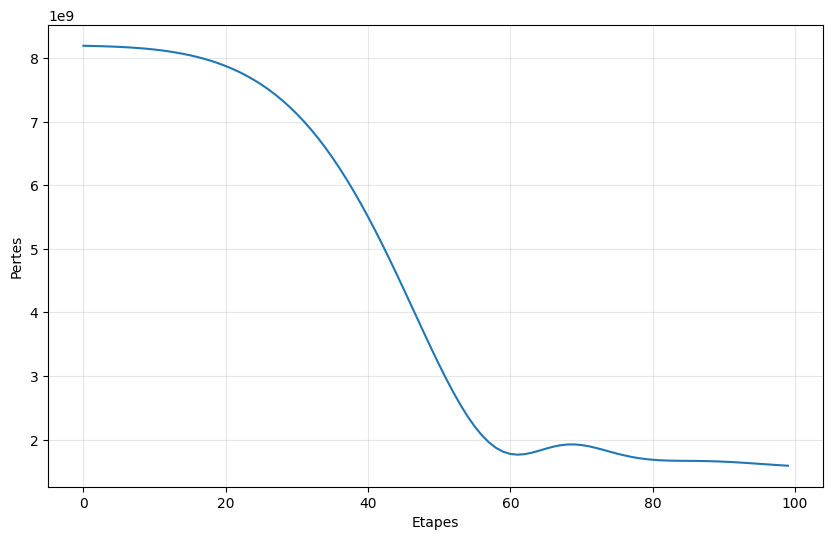

In [31]:
# trainning
loss_fn = nn.MSELoss()
optim_fn = optim.Adam(model.parameters(),lr=0.01)
losses = []

for epoch in range (100):
    
    # forward
    y_pred = model(x_train)
    loss = loss_fn(y_pred,y_train)
    losses.append(loss.item())
    
    # backward
    optim_fn.zero_grad()
    loss.backward()
    optim_fn.step()
    
    if epoch %10 == 0:
        print(f"Etape {epoch} : perte = {loss:.4f}")

    with torch.no_grad():
        y_pred_test = model(x_test)
        
        
        
print(f"mae = {r2_score(y_pred_test,y_test)}")
plt.figure(figsize=(10,6))
plt.plot(losses)
plt.grid(True,alpha=0.3)
plt.xlabel('Etapes')
plt.ylabel('Pertes')



